In [1]:
import numpy as np
import matplotlib.pyplot as plt

from floris import FlorisModel

fmodel = FlorisModel("gch.yaml")
x, y = fmodel.get_turbine_layout()

print("     x       y")
for _x, _y in zip(x, y):
    print(f"{_x:6.1f}, {_y:6.1f}")

     x       y
   0.0,    0.0
 630.0,    0.0
1260.0,    0.0


In [2]:
x_2x2 = [0, 0, 800, 800]
y_2x2 = [0, 400, 0, 400]
fmodel.set(layout_x=x_2x2, layout_y=y_2x2)

x, y = fmodel.get_turbine_layout()

print("     x       y")
for _x, _y in zip(x, y):
    print(f"{_x:6.1f}, {_y:6.1f}")

     x       y
   0.0,    0.0
   0.0,  400.0
 800.0,    0.0
 800.0,  400.0


In [3]:
fmodel.set(wind_directions=[270.0], wind_speeds=[8.0], turbulence_intensities=[0.1])

fmodel.set(
    wind_directions=[270.0, 280.0],
    wind_speeds=[8.0, 8.0],
    turbulence_intensities=[0.1, 0.1],
)

fmodel.set(
    wind_directions=[270.0, 280.0, 270.0, 280.0],
    wind_speeds=[8.0, 8.0, 9.0, 9.0],
    turbulence_intensities=[0.1, 0.1, 0.1, 0.1],
)

In [4]:
np.array(
    (
        findex,
        turbines,
        grid-1,
        grid-2
    )
)

NameError: name 'findex' is not defined

Dimensions of grid x-components
(4, 4, 3, 3)

3rd turbine x-components for first wind condition (at findex=0)
[[800. 800. 800.]
 [800. 800. 800.]
 [800. 800. 800.]]


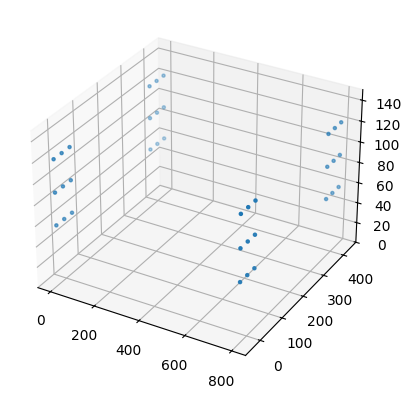

In [ ]:
print("Dimensions of grid x-components")
print(np.shape(fmodel.core.grid.x_sorted))

print()
print("3rd turbine x-components for first wind condition (at findex=0)")
print(fmodel.core.grid.x_sorted[0, 2, :, :])

x = fmodel.core.grid.x_sorted[0, :, :, :]
y = fmodel.core.grid.y_sorted[0, :, :, :]
z = fmodel.core.grid.z_sorted[0, :, :, :]

fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x, y, z, marker=".")
ax.set_zlim([0, 150])
plt.show()

In [ ]:
fmodel.run()

In [ ]:
powers = fmodel.get_turbine_powers() / 1000.0  # calculated in Watts, so convert to kW

print("Dimensions of `powers`")
print( np.shape(powers) )

N_TURBINES = fmodel.core.farm.n_turbines

print()
print("Turbine powers for 8 m/s")
for i in range(2):
    print(f"Wind condition {i}")
    for j in range(N_TURBINES):
        print(f"  Turbine {j} - {powers[i, j]:7,.2f} kW")
    print()

print("Turbine powers for all turbines at all wind conditions")
print(powers)

Dimensions of `powers`
(4, 4)

Turbine powers for 8 m/s
Wind condition 0
  Turbine 0 - 1,753.95 kW
  Turbine 1 - 1,753.95 kW
  Turbine 2 -  904.68 kW
  Turbine 3 -  904.85 kW

Wind condition 1
  Turbine 0 - 1,753.95 kW
  Turbine 1 - 1,753.95 kW
  Turbine 2 - 1,644.86 kW
  Turbine 3 - 1,643.39 kW

Turbine powers for all turbines at all wind conditions
[[1753.95445918 1753.95445918  904.68478734  904.84672946]
 [1753.95445918 1753.95445918 1644.85720431 1643.39012544]
 [2496.42786184 2496.42786184 1276.4580679  1276.67310219]
 [2496.42786184 2496.42786184 2354.40522998 2352.47398836]]
